# Phase 5A — validation input preparation

**Status: completed and independently verified.** This report summarizes the private Phase 5A run without publishing its audio, manifests, source locators, or provenance map.

The phase packaged the frozen validation split for the later zero-shot baseline. It verified that all selected clips and references were copied intact. **No model inference, CER scoring, or training was run.**

The component labels shown in the validation bundle are stable aliases for the existing split groups. They are not proof of expert-verified speaker identities. See the full [Phase 5A report](../docs/PHASE5A_RESULTS.md) for the Parquet shard/row-group explanation and limitations.

## Aggregate outcome



In [1]:
from pathlib import Path
import json

# Read only public aggregate Phase 5A metrics; no audio or private manifest is used.
metrics_path = Path('../docs/PHASE5A_RESULTS_AGGREGATE.json')
metrics = json.loads(metrics_path.read_text(encoding='utf-8'))
print('Phase 5A: completed and independently verified')
print(f"Validation: {metrics['validation_clips']} clips | {metrics['validation_hours']:.6f} hours | {metrics['validation_components']} components")
print(f"Reference denominator: {metrics['reference_codepoints_nfd_including_spaces']:,} NFD code points, including spaces")
print(f"Audio integrity: {metrics['decoded_audio_verified']} passed | {metrics['extraction_errors']} extraction errors")
print(f"Checksums: {metrics['payload_hashes_verified']} payload files passed | {metrics['zip_entries_including_checksum_list']} ZIP members")
print(f"Private ZIP: {metrics['private_zip_size_bytes'] / (1024 ** 2):.2f} MiB | SHA-256 {metrics['private_zip_sha256']}")
print(f"Inference/CER/training: {'run' if metrics['inference_run'] else 'not run'}/{'run' if metrics['cer_computed'] else 'not run'}/{'run' if metrics['training_run'] else 'not run'}")


Phase 5A: completed and independently verified\nValidation: 732 clips | 1.881808 hours | 16 components\nReference denominator: 64,137 NFD code points, including spaces\nAudio integrity: 732 passed | 0 extraction errors\nChecksums: 737 payload files passed | 738 ZIP members\nPrivate ZIP: 138.64 MiB | SHA-256 2a7cb19aac3707488733b9af8bd70b694f969583e1fbe03de2a9f39466954f52\nInference/CER/training: not run\n

## Figure 1 — clip duration and reference length

This shows how clip lengths and reference lengths are distributed. Outliers are prompts for later review, not evidence by themselves that a transcript is wrong.


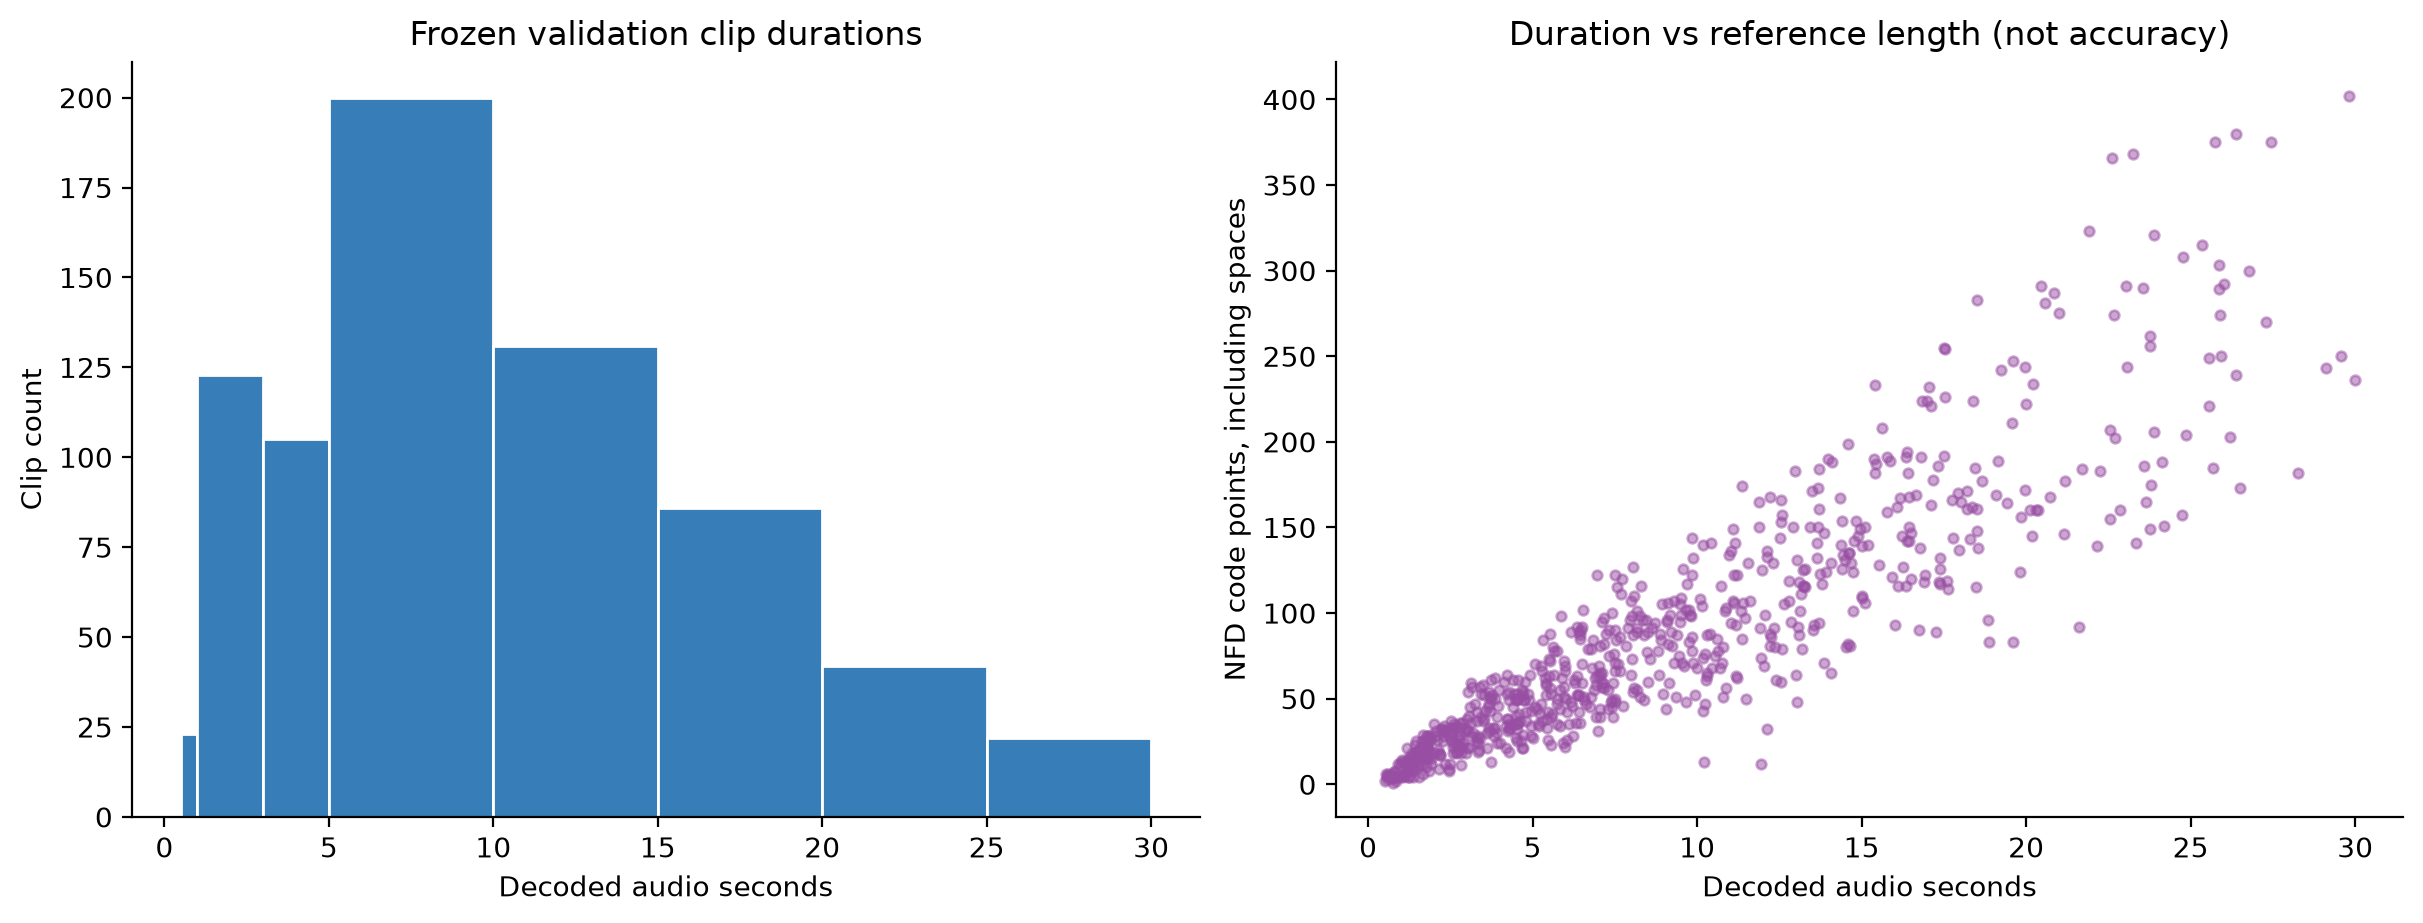

In [2]:
from IPython.display import Image, display
display(Image(filename='../assets/phase5a/01_validation_duration_and_reference_length.png'))


## Figure 2 — audio hours by validation group

These are anonymized component aliases. Unequal group sizes should be considered when interpreting group-level validation errors.


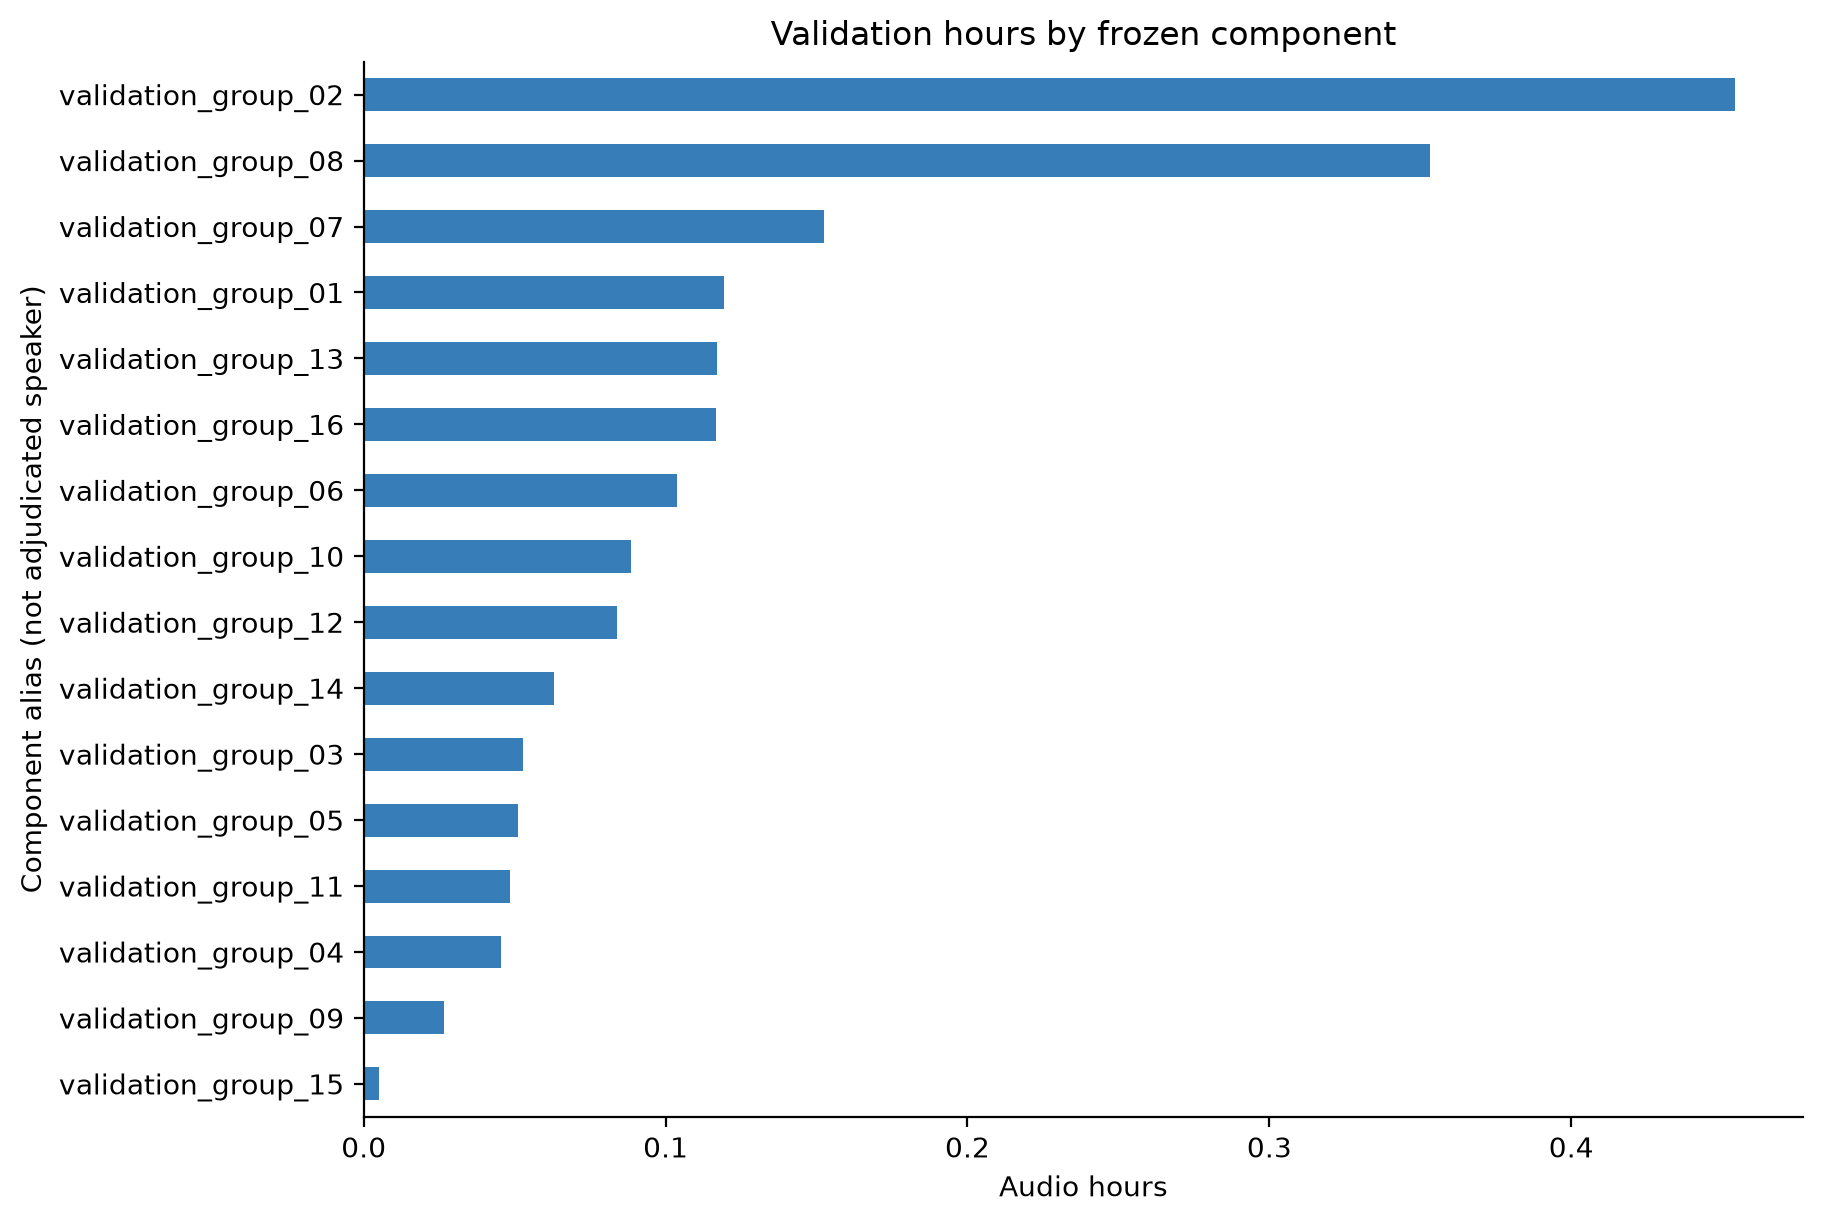

In [3]:
display(Image(filename='../assets/phase5a/02_validation_component_hours.png'))


## Figure 3 — metadata coverage

Metadata distributions describe coverage of this frozen validation split; they are not a target for changing the split after evaluation begins.


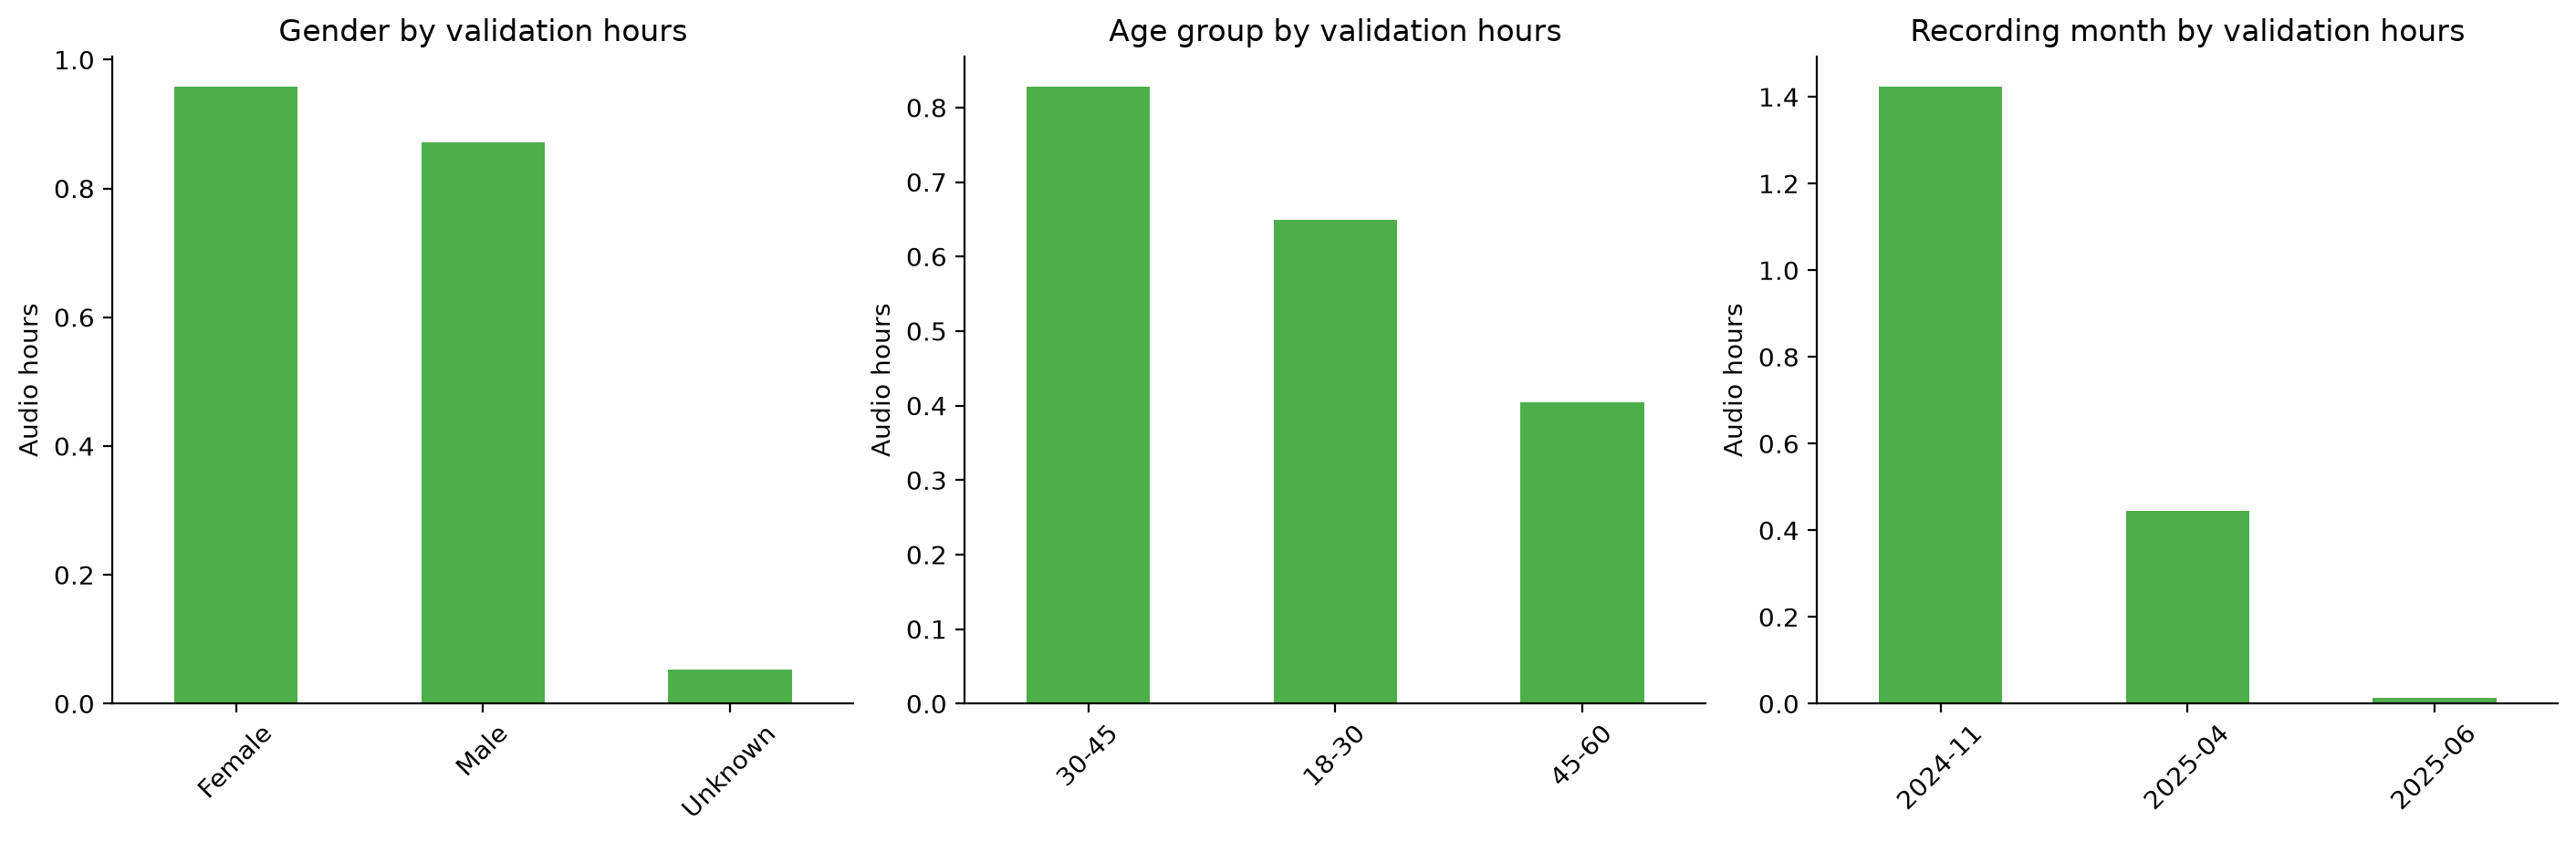

In [4]:
display(Image(filename='../assets/phase5a/03_validation_metadata_coverage.png'))


## Conclusion and next step

All **732 frozen validation clips** were decoded and verified, and all **737 payload checksums** passed. This confirms that the prepared inputs are ready for the next evaluation step; it does not establish transcript correctness or model accuracy.

Next: upload the ZIP privately to Kaggle, verify its checksums there, then run Phase 5B scoring checks, a small preflight, and the full zero-shot baseline on validation. Keep the frozen test set reserved. The private WAV bundle and locator/provenance records are intentionally not included in this repository.
